In [29]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [217]:
data_path = "C:\\AI Equipment Failure Prediction\\data\\22_열처리.csv"
df = pd.read_csv(data_path)

In [59]:
df.head()

,timestamp,설비,제어출력,소입로온도
0,2024-03-01 09:00:00,1,0.426,861.05
1,2024-03-01 09:00:10,1,0.463,860.99
2,2024-03-01 09:00:20,1,0.438,861.05
3,2024-03-01 09:00:30,1,0.445,861.05
4,2024-03-01 09:00:40,1,0.421,861.11


In [32]:
df.shape

(188, 4)

In [63]:
df.isna().sum()

설비       0
제어출력     0
소입로온도    0
dtype: int64

In [6]:
#diff().dt.total_seconds()
#asfreq

In [61]:
df.columns

Index(['timestamp', '설비', '제어출력', '소입로온도'], dtype='str')

In [62]:
df['timestamp'] = pd.to_datetime(df['timestamp'], 
                                 format='%Y-%m-%d %H:%M:%S', errors='coerce')
df.set_index('timestamp', inplace=True)
df.sort_index(inplace=True)

In [37]:
df.index

DatetimeIndex(['2024-03-01 09:00:00', '2024-03-01 09:00:10',
               '2024-03-01 09:00:20', '2024-03-01 09:00:30',
               '2024-03-01 09:00:40', '2024-03-01 09:00:50',
               '2024-03-01 09:01:00', '2024-03-01 09:01:10',
               '2024-03-01 09:01:20', '2024-03-01 09:01:30',
               ...
               '2024-03-01 09:31:40', '2024-03-01 09:31:50',
               '2024-03-01 09:32:00', '2024-03-01 09:32:10',
               '2024-03-01 09:32:20', '2024-03-01 09:32:30',
               '2024-03-01 09:32:40', '2024-03-01 09:32:50',
               '2024-03-01 09:33:00', '2024-03-01 09:33:10'],
              dtype='datetime64[us]', name='timestamp', length=188, freq=None)

In [40]:
#초의 간격을 파악하는 코드
print(df.index.to_series().diff().dt.total_seconds().sort_values(ascending=False))

timestamp
2024-03-01 09:11:10    80.0
2024-03-01 09:05:11    21.0
2024-03-01 09:02:40    20.0
2024-03-01 09:08:00    20.0
2024-03-01 09:28:30    20.0
                       ... 
2024-03-01 09:05:42     7.0
2024-03-01 09:06:45     5.0
2024-03-01 09:06:50     5.0
2024-03-01 09:06:17     3.0
2024-03-01 09:00:00     NaN
Name: timestamp, Length: 188, dtype: float64


In [42]:
df.index.diff().value_counts()

timestamp
0 days 00:00:10    169
0 days 00:00:20      5
0 days 00:00:07      3
0 days 00:00:05      2
0 days 00:00:21      1
0 days 00:00:17      1
0 days 00:00:12      1
0 days 00:00:13      1
0 days 00:00:03      1
0 days 00:00:14      1
0 days 00:00:09      1
0 days 00:01:20      1
Name: count, dtype: int64

In [44]:
gaps = df.index.to_series().diff().dt.total_seconds()

In [46]:
gaps.value_counts().sort_values(ascending=False)

timestamp
10.0    169
20.0      5
7.0       3
5.0       2
21.0      1
17.0      1
12.0      1
13.0      1
3.0       1
14.0      1
9.0       1
80.0      1
Name: count, dtype: int64

In [64]:
norm = df['제어출력'].asfreq('10s')

In [65]:
df.isna().sum()

설비       0
제어출력     0
소입로온도    0
dtype: int64

In [66]:
norm.isna().sum()

np.int64(22)

In [67]:
df.iloc[13:18]

,설비,제어출력,소입로온도
timestamp,,,
2024-03-01 09:02:10,1,0.393,861.31
2024-03-01 09:02:20,1,0.401,861.31
2024-03-01 09:02:40,1,0.409,861.31
2024-03-01 09:02:50,1,0.387,861.38
2024-03-01 09:03:00,1,0.394,861.38


In [68]:
norm.iloc[13:18]

timestamp
2024-03-01 09:02:10    0.393
2024-03-01 09:02:20    0.401
2024-03-01 09:02:30      NaN
2024-03-01 09:02:40    0.409
2024-03-01 09:02:50    0.387
Freq: 10s, Name: 제어출력, dtype: float64

In [69]:
gap_norm = norm.index.to_series().diff().dt.total_seconds()

In [72]:
gap_norm.value_counts().sort_index()

timestamp
10.0    199
Name: count, dtype: int64

In [73]:
df.isna().sum()

설비       0
제어출력     0
소입로온도    0
dtype: int64

In [74]:
#1

In [96]:
df = pd.read_csv(data_path)
df['timestamp'] = pd.to_datetime(df['timestamp'])
df = df.set_index('timestamp').sort_index()

In [99]:
one_min = df[['제어출력', '소입로온도']].resample('min').mean()
print(one_min.head(3).round(2))
print('1분 평균 빈 칸 :', int(one_min['제어출력'].isna().sum()))


                     제어출력   소입로온도
timestamp                        
2024-03-01 09:00:00  0.44  861.06
2024-03-01 09:01:00  0.42  861.18
2024-03-01 09:02:00  0.40  861.31
1분 평균 빈 칸 : 1


In [101]:
from datetime import datetime, timezone

In [110]:
from zoneinfo import ZoneInfo

In [106]:
unixtime = 1793756388

In [104]:
timezone.utc

datetime.timezone.utc

In [111]:
print(datetime.fromtimestamp(unixtime, ZoneInfo("Asia/Seoul")))

2026-11-04 10:39:48+09:00


In [112]:
#실습2

In [113]:
# 시각끼리 빼서 초 단위 차이 구하기
sec = df.index.to_series().diff().dt.total_seconds()
# 간격별 개수를 정렬해서 확인
print(sec.value_counts().sort_index().head())

timestamp
3.0       1
5.0       2
7.0       3
9.0       1
10.0    169
Name: count, dtype: int64


In [123]:
sec.value_counts()

timestamp
10.0    169
20.0      5
7.0       3
5.0       2
21.0      1
17.0      1
12.0      1
13.0      1
3.0       1
14.0      1
9.0       1
80.0      1
Name: count, dtype: int64

In [124]:
sec.sort_values(ascending=False).head()

timestamp
2024-03-01 09:11:10    80.0
2024-03-01 09:05:11    21.0
2024-03-01 09:02:40    20.0
2024-03-01 09:08:00    20.0
2024-03-01 09:28:30    20.0
Name: timestamp, dtype: float64

In [125]:
#실습3

In [129]:
cols = ['제어출력', '소입로온도']

In [130]:
df_asf = df[cols].asfreq('10s')


In [138]:
len(df)

188

In [131]:
len(df_asf)

200

In [137]:
df_asf.isna().sum().sum() #처리전

np.int64(44)

In [134]:
df_assff=df_asf.ffill()

In [ ]:
df_assff.isna().sum().sum() # 처리후

np.int64(0)

In [143]:
df.head()

,설비,제어출력,소입로온도
timestamp,,,
2024-03-01 09:00:00,1,0.426,861.05
2024-03-01 09:00:10,1,0.463,860.99
2024-03-01 09:00:20,1,0.438,861.05
2024-03-01 09:00:30,1,0.445,861.05
2024-03-01 09:00:40,1,0.421,861.11


In [147]:
norm1=df[['제어출력']].asfreq('10s')

In [148]:
norm1.head()

,제어출력
timestamp,
2024-03-01 09:00:00,0.426
2024-03-01 09:00:10,0.463
2024-03-01 09:00:20,0.438
2024-03-01 09:00:30,0.445
2024-03-01 09:00:40,0.421


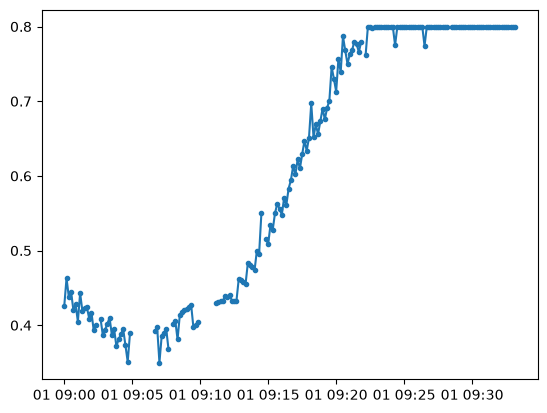

In [151]:
# 점 + 선으로 함께 그려야 빈 구간이 보임
plt.plot(norm1.index, norm1["제어출력"], marker=".")
plt.show()

In [ ]:
#제어출력, 소입로온도
#실습4

In [154]:
df.isna().sum()


설비       0
제어출력     0
소입로온도    0
dtype: int64

In [160]:
norm1.isna().sum()

제어출력    22
dtype: int64

In [161]:
norm1.isna().sum().to_dict()

{'제어출력': 22}

In [168]:
print('결측 비율(%):',norm1.isna().mean() * 100)

결측 비율(%): 제어출력    11.0
dtype: float64


In [174]:
miss = norm1[norm1['제어출력'].isna()].index
print('빈  시각  개수 :', len(miss), '/ 첫  구간 :', miss[0]) 

빈  시각  개수 : 22 / 첫  구간 : 2024-03-01 09:02:30


In [175]:
#실습5

In [ ]:
norm1 #asf 10s

,제어출력
timestamp,
2024-03-01 09:00:00,0.426
2024-03-01 09:00:10,0.463
2024-03-01 09:00:20,0.438
2024-03-01 09:00:30,0.445
2024-03-01 09:00:40,0.421
...,...
2024-03-01 09:32:30,0.800
2024-03-01 09:32:40,0.800
2024-03-01 09:32:50,0.800


In [178]:
norm2 = df[['제어출력']].resample('10s').mean()

In [181]:
print('격자올리기 결측수:', norm1.isna().sum())
print('구간묶기 결측수:', norm2.isna().sum())

격자올리기 결측수: 제어출력    22
dtype: int64
구간묶기 결측수: 제어출력    16
dtype: int64


In [182]:
norm2_1min=norm2.resample('min').mean()
print('1분 단위 결측수:', norm2_1min.isna().sum())

1분 단위 결측수: 제어출력    1
dtype: int64


In [183]:
# 실습6

In [ ]:
df.shape # 원본

(188, 3)

In [186]:
norm1.shape #asfreq 10s

(200, 1)

In [187]:
norm2.shape #resample 10s

(200, 1)

In [189]:
norm2_1min.shape #norm2 resample 1min

(34, 1)

In [190]:
#결측 갯수와 비율

In [193]:
print('격자올리기 결측개수 :', norm1.isna().sum())
print('구간묶기 결측개수 :', norm2.isna().sum())
print('1분 리샘플 결측개수 :', norm2_1min.isna().sum())

print('격자올리기 결측비율 :', norm1.isna().sum() / len(norm1))
print('구간묶기 결측비율 :', norm2.isna().sum() / len(norm2))
print('1분 리샘플 결측비율 :', norm2_1min.isna().sum() / len(norm2_1min))


격자올리기 결측개수 : 제어출력    22
dtype: int64
구간묶기 결측개수 : 제어출력    16
dtype: int64
1분 리샘플 결측개수 : 제어출력    1
dtype: int64
격자올리기 결측비율 : 제어출력    0.11
dtype: float64
구간묶기 결측비율 : 제어출력    0.08
dtype: float64
1분 리샘플 결측비율 : 제어출력    0.029412
dtype: float64


In [194]:
df.columns

Index(['설비', '제어출력', '소입로온도'], dtype='str')

In [ ]:
#colums 바꾸기
df.columns = ['설비2', '제어출력2', '소입로온도2']
df.columns



Index(['설비2', '제어출력2', '소입로온도2'], dtype='str')

In [197]:
#colums 바꾸기
df.columns = ['설비', '제어출력', '소입로온도']
df.columns


Index(['설비', '제어출력', '소입로온도'], dtype='str')

In [ ]:
pd.merge

In [199]:
norm.isna().sum()

np.int64(22)

In [209]:
#실습1

In [218]:
df = pd.read_csv(data_path)
df['timestamp'] = pd.to_datetime(df['timestamp'])

In [220]:
df = df.set_index('timestamp').sort_index()

In [223]:
norm = df[['제어출력', '소입로온도']].asfreq('10s')

In [227]:
normf=norm.ffill()
normb=norm.bfill()
print('앞으로 채우기  :', normf.isna().sum())
print('뒤로 채우기  :', normb.isna().sum())

앞으로 채우기  : 제어출력     0
소입로온도    0
dtype: int64
뒤로 채우기  : 제어출력     0
소입로온도    0
dtype: int64


In [229]:
normfb=norm.ffill().bfill()
print('앞뒤로 채우기 결측 :', normfb.isna().sum())

앞뒤로 채우기 결측 : 제어출력     0
소입로온도    0
dtype: int64


In [204]:
s = pd.Series([10.0, np.nan, 40.0], index=pd.to_datetime(
    ['2024-03-01 09:00:00', '2024-03-01 09:00:10', '2024-03-01 09:01:00']))

In [205]:
s

2024-03-01 09:00:00    10.0
2024-03-01 09:00:10     NaN
2024-03-01 09:01:00    40.0
dtype: float64

In [206]:
s.interpolate(method='linear')

2024-03-01 09:00:00    10.0
2024-03-01 09:00:10    25.0
2024-03-01 09:01:00    40.0
dtype: float64

In [208]:
s.interpolate(method='time')

2024-03-01 09:00:00    10.0
2024-03-01 09:00:10    15.0
2024-03-01 09:01:00    40.0
dtype: float64

In [230]:
#실습2

In [231]:
norm.isna().sum()

제어출력     22
소입로온도    22
dtype: int64

In [ ]:
# interpolate 선형보간
# interpolate liner time 시간 김반 보간

In [232]:
norm_linear = norm.interpolate(method='linear')
norm_time = norm.interpolate(method='time')

In [233]:
print('선형보간 결측 :', norm_linear.isna().sum())
print('시간보간 결측 :', norm_time.isna().sum())

선형보간 결측 : 제어출력     0
소입로온도    0
dtype: int64
시간보간 결측 : 제어출력     0
소입로온도    0
dtype: int64


In [239]:
#norm_time.value_counts()
norm_linear.value_counts()

제어출력   소입로온도 
0.433  861.78    3
0.800  858.58    3
       857.16    3
0.432  861.78    2
0.800  859.31    2
                ..
       857.59    1
       857.30    1
       857.10    1
       857.11    1
       857.05    1
Name: count, Length: 179, dtype: int64

In [234]:
print('시간보간과 선형보간이 같은가?', norm_time.equals(norm_linear))

시간보간과 선형보간이 같은가? True


In [240]:
(norm_time != norm_linear).sum()

제어출력     0
소입로온도    0
dtype: int64

In [242]:
norm.isna().sum() 

제어출력     22
소입로온도    22
dtype: int64

In [243]:
limited = norm['제어출력'].interpolate(limit=2)
limited.isna().sum()

np.int64(13)

In [244]:
#실습3

In [247]:
norm['제어출력'].isna().where(norm['제어출력'].isna())

timestamp
2024-03-01 09:00:00    NaN
2024-03-01 09:00:10    NaN
2024-03-01 09:00:20    NaN
2024-03-01 09:00:30    NaN
2024-03-01 09:00:40    NaN
                      ... 
2024-03-01 09:32:30    NaN
2024-03-01 09:32:40    NaN
2024-03-01 09:32:50    NaN
2024-03-01 09:33:00    NaN
2024-03-01 09:33:10    NaN
Freq: 10s, Name: 제어출력, Length: 200, dtype: object

In [250]:
#연속 결측 길이 구하기
norm['제어출력'].isna().astype(int).groupby(norm['제어출력'].notna().astype(int).cumsum()).sum().isna()

제어출력
1      False
2      False
3      False
4      False
5      False
       ...  
174    False
175    False
176    False
177    False
178    False
Name: 제어출력, Length: 178, dtype: bool

In [ ]:
from itertools import groupby

isna = norm['제어출력 '].isna()  # 결측이면 True, 아니면 False

# 값이 같은 것끼리 묶은 뒤, True(결측) 묶음의 길이만 모음
runs = [sum(1 for _ in g) for is_na, g in groupby(isna) if is_na]

print('연속 결측 길이:', sorted(runs, reverse=True))


In [253]:
#실습4

In [255]:
norm.head()

,제어출력,소입로온도
timestamp,,
2024-03-01 09:00:00,0.426,861.05
2024-03-01 09:00:10,0.463,860.99
2024-03-01 09:00:20,0.438,861.05
2024-03-01 09:00:30,0.445,861.05
2024-03-01 09:00:40,0.421,861.11


In [257]:
norm.isna().sum()

제어출력     22
소입로온도    22
dtype: int64

In [258]:
normt = norm.interpolate(method='time')
normt.isna().sum()

제어출력     0
소입로온도    0
dtype: int64

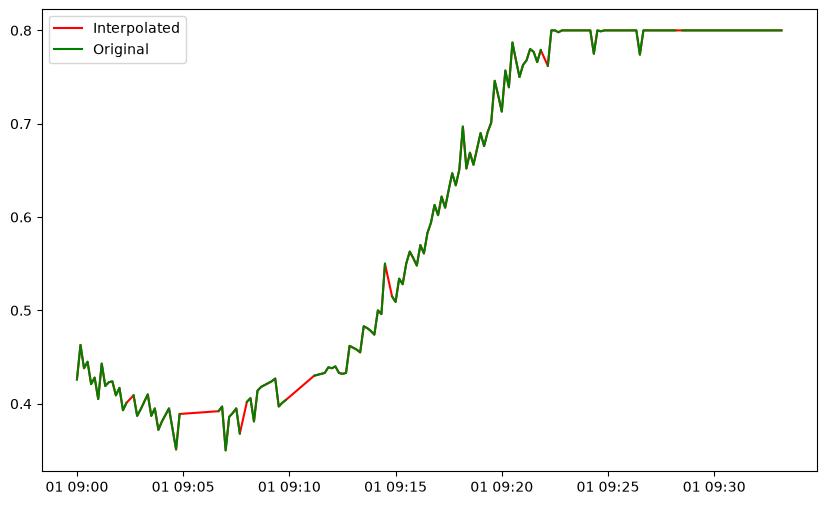

In [269]:
plt.figure(figsize=(10, 6))

plt.plot(normt.index, normt['제어출력'], label='Interpolated', color='r')
plt.plot(norm.index, norm['제어출력'], label='Original', color='g')
plt.legend()
plt.show()




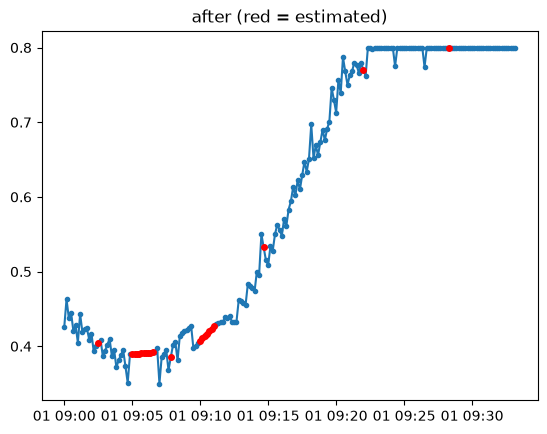

In [273]:
was_na = norm['제어출력'].isna()
plt.plot(restored.index, restored['제어출력'], marker='.')
plt.plot(restored.index[was_na], restored['제어출력'][was_na], 'ro', 
markersize=4)
plt.title('after (red = estimated)'); plt.show()


In [274]:
#실습 5

In [287]:
#러오기 ·정규화 ·시간  보간을  한  함수로  묶어  자동화
def preprocess_data(file_path, freq='10s'):
    df = pd.read_csv(file_path)
    df['timestamp'] = pd.to_datetime(df['timestamp']) #향후수정필요
    df = df.set_index('timestamp').sort_index()

    good = df[['제어출력','소입로온도']].asfreq(freq)
    print('전', good.isna().sum().to_dict())

    clean = good.interpolate(method='time')
    print('후', clean.isna().sum().to_dict())

    return clean

In [288]:
clean = preprocess_data("C:\\AI Equipment Failure Prediction\\data\\22_열처리.csv")
print(clean.head())

전 {'제어출력': 22, '소입로온도': 22}
후 {'제어출력': 0, '소입로온도': 0}
                      제어출력   소입로온도
timestamp                         
2024-03-01 09:00:00  0.426  861.05
2024-03-01 09:00:10  0.463  860.99
2024-03-01 09:00:20  0.438  861.05
2024-03-01 09:00:30  0.445  861.05
2024-03-01 09:00:40  0.421  861.11


In [277]:
#실습6

In [289]:
#러오기 ·정규화 ·시간  보간을  한  함수로  묶어  자동화
def preprocess_data(file_path, freq='10s'):
    df = pd.read_csv(file_path)
    df['timestamp'] = pd.to_datetime(df['timestamp']) #향후수정필요
    df = df.set_index('timestamp').sort_index()

    good = df[['제어출력','소입로온도']].asfreq(freq)
    print('전', good.isna().sum().to_dict())
    print(good.shape)

    clean = good.interpolate(method='time')
    print('후', clean.isna().sum().to_dict())
    print(clean.shape)

    return clean

In [ ]:
for i in ['10s', '30s', '1min']:
    clean = preprocess_data("C:\\AI Equipment Failure Prediction\\data\\22_열처리.csv", freq=i)
    print(clean.head(1))


전 {'제어출력': 22, '소입로온도': 22}
(200, 2)
후 {'제어출력': 0, '소입로온도': 0}
(200, 2)
                      제어출력   소입로온도
timestamp                         
2024-03-01 09:00:00  0.426  861.05
전 {'제어출력': 9, '소입로온도': 9}
(67, 2)
후 {'제어출력': 0, '소입로온도': 0}
(67, 2)
                      제어출력   소입로온도
timestamp                         
2024-03-01 09:00:00  0.426  861.05
전 {'제어출력': 5, '소입로온도': 5}
(34, 2)
후 {'제어출력': 0, '소입로온도': 0}
(34, 2)
                      제어출력   소입로온도
timestamp                         
2024-03-01 09:00:00  0.426  861.05


In [295]:
import pygame

ModuleNotFoundError: No module named 'pygame'

In [293]:
pip install pygame

     ---------------------------------------- 0.0/14.8 MB ? eta -:--:--
     ----------- ---------------------------- 4.2/14.8 MB 41.2 MB/s eta 0:00:01
     -------------------------- ------------ 10.2/14.8 MB 30.0 MB/s eta 0:00:01
     ---------------------------------------- 14.8/14.8 MB 34.0 MB/s  0:00:00
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'error'
Note: you may need to restart the kernel to use updated packages.


  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> [112 lines of output]
      Skipping Cython compilation
      
      
      WARNING, No "Setup" File Exists, Running "buildconfig/config.py"
      Using WINDOWS configuration...
      
      Making dir :prebuilt_downloads:
      Downloading... https://www.libsdl.org/release/SDL2-devel-2.28.4-VC.zip 25ef9d201ce3fd5f976c37dddedac36bd173975c
      Unzipping :prebuilt_downloads\SDL2-devel-2.28.4-VC.zip:
      Downloading... https://www.libsdl.org/projects/SDL_image/release/SDL2_image-devel-2.0.5-VC.zip 137f86474691f4e12e76e07d58d5920c8d844d5b
      Unzipping :prebuilt_downloads\SDL2_image-devel-2.0.5-VC.zip:
      Downloading... https://github.com/libsdl-org/SDL_ttf/releases/download/release-2.20.1/SDL2_ttf-devel-2.20.1-VC.zip 371606aceba450384428fd2852f73d2f6290b136
      Unzipping :prebuilt_downloads\SDL2_ttf-devel-2.20.1-VC.zip:
      Downloading... https://g

In [304]:
#class 기초

In [298]:
class Car :
    pass

In [309]:
Car

__main__.Car

In [303]:
first_car = Car()
Car()

In [307]:
print(Car)

<class '__main__.Car'>


In [308]:
print(type(first_car))

<class '__main__.Car'>


In [310]:
#step 2

In [311]:
class Car:
    def roll():
        print("The car is rolling")

In [320]:
first_car = Car()

In [ ]:
first_car.roll()

TypeError: Car.roll() takes 0 positional arguments but 1 was given

In [318]:
class Car:
    def roll(self):
        print("The car is rolling")

In [322]:
first_car = Car()

In [323]:
first_car.roll()

The car is rolling


In [324]:
#step 3

In [325]:
class Car:
    def __init__(self, color):
        self.color = color
    def roll(self):
        print("The car is rolling")

In [332]:
third_car = Car() #color 가빠짐

TypeError: Car.__init__() missing 1 required positional argument: 'color'

In [331]:
third_car = Car('철강색')
third_car.color

'철강색'